# Wall Segmentation + Normal Vector Analysis

This notebook helps visualize and analyze RGB->X model outputs (normal vectors) and will later integrate with SegFormer for wall segmentation.

## 1. Setup & Configuration
Configure all paths here - update these with your actual paths

In [1]:
# Path configurations - UPDATE THESE
INPUT_IMAGES_DIR = "/Users/ishan-aiworkspace/Documents/apps/rgb-x/normal_irradiance/sample_images"  # Directory with original RGB images
RGBX_OUTPUTS_DIR = "/Users/ishan-aiworkspace/Documents/apps/rgb-x/rgb-x_output/batch_output"  # Directory with .npy files from RGB->X model
EXTERNAL_MODULE_PATH = "/Users/ishan-aiworkspace/Documents/apps/ST-RoomNet-for-visualisation/workflow-v3-research-driven/modules"  # Path to directory containing SegFormer module
OUTPUT_DIR = "/Users/ishan-aiworkspace/Documents/apps/rgb-x/rgb-x_output/batch_output"  # Where to save visualizations and results

# File extension for RGB->X outputs
NORMAL_NPY_SUFFIX = "normal.npy"  # Adjust based on your naming convention

print(f"Input images: {INPUT_IMAGES_DIR}")
print(f"RGB->X outputs: {RGBX_OUTPUTS_DIR}")
print(f"External module: {EXTERNAL_MODULE_PATH}")
print(f"Output directory: {OUTPUT_DIR}")

Input images: /Users/ishan-aiworkspace/Documents/apps/rgb-x/normal_irradiance/sample_images
RGB->X outputs: /Users/ishan-aiworkspace/Documents/apps/rgb-x/rgb-x_output/batch_output
External module: /Users/ishan-aiworkspace/Documents/apps/ST-RoomNet-for-visualisation/workflow-v3-research-driven/modules
Output directory: /Users/ishan-aiworkspace/Documents/apps/rgb-x/rgb-x_output/batch_output


## 2. Import Dependencies

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import os
from pathlib import Path
import sys

# Add external module to path (for future SegFormer import)
if EXTERNAL_MODULE_PATH not in sys.path:
    sys.path.insert(0, EXTERNAL_MODULE_PATH)
    print(f"Added {EXTERNAL_MODULE_PATH} to Python path")

# Create output directory if it doesn't exist
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("All dependencies imported successfully!")

Added /Users/ishan-aiworkspace/Documents/apps/ST-RoomNet-for-visualisation/workflow-v3-research-driven/modules to Python path
All dependencies imported successfully!


## 3. Build Data Structure for Input-Output Mapping
Match input images with their corresponding output files

In [17]:
def build_image_dataset():
    """
    Build a data structure that maps input images to their corresponding output files.
    
    Folder structure expected:
    - INPUT_IMAGES_DIR/
        - image1.jpg
        - image2.jpeg
        - image3.jpg
    - RGBX_OUTPUTS_DIR/
        - image1/
            - normal.npy
            - irradiance.npy
            - wall_confidence.npy (optional, from SegFormer)
        - image2/
            - normal.npy
            - irradiance.npy
            - wall_confidence.npy (optional, from SegFormer)
    
    Returns:
        list of dicts: Each dict contains:
            - 'image_name': str, base name without extension
            - 'input_path': Path object to input image
            - 'normal_path': Path object to normal.npy (or None if not found)
            - 'irradiance_path': Path object to irradiance.npy (or None if not found)
            - 'wall_confidence_path': Path object to wall_confidence.npy (or None if not found)
            - 'has_complete_outputs': bool, True if both normal and irradiance exist
            - 'has_segmentation': bool, True if wall_confidence exists
    """
    dataset = []
    
    # Find all output subdirectories (each named after an input image)
    output_subdirs = [d for d in Path(RGBX_OUTPUTS_DIR).iterdir() if d.is_dir()]
    
    print(f"Found {len(output_subdirs)} output subdirectories in {RGBX_OUTPUTS_DIR}")
    
    for subdir in output_subdirs:
        image_name = subdir.name  # This should match the input image name (without extension)
        
        # Look for the corresponding input image
        input_path = None
        for ext in ['.jpg', '.jpeg', '.JPG', '.JPEG', '.png', '.PNG']:
            potential_input = Path(INPUT_IMAGES_DIR) / f"{image_name}{ext}"
            if potential_input.exists():
                input_path = potential_input
                break
        
        # Look for output files in the subdirectory
        normal_path = subdir / f"{image_name}_normal.npy"
        irradiance_path = subdir / f"{image_name}_irradiance.npy"
        wall_confidence_path = subdir / f"{image_name}_wall_confidence.npy"
        
        # Check if outputs exist
        normal_exists = normal_path.exists()
        irradiance_exists = irradiance_path.exists()
        wall_confidence_exists = wall_confidence_path.exists()
        
        # Create entry
        entry = {
            'image_name': image_name,
            'input_path': input_path,
            'normal_path': normal_path if normal_exists else None,
            'irradiance_path': irradiance_path if irradiance_exists else None,
            'wall_confidence_path': wall_confidence_path if wall_confidence_exists else None,
            'has_complete_outputs': normal_exists and irradiance_exists,
            'has_segmentation': wall_confidence_exists
        }
        
        dataset.append(entry)
    
    return dataset

# Build the dataset
image_dataset = build_image_dataset()

print(f"\n{'='*70}")
print(f"DATASET SUMMARY")
print(f"{'='*70}")
print(f"Total entries: {len(image_dataset)}")

# Count statistics
with_input = sum(1 for item in image_dataset if item['input_path'] is not None)
with_normal = sum(1 for item in image_dataset if item['normal_path'] is not None)
with_irradiance = sum(1 for item in image_dataset if item['irradiance_path'] is not None)
with_segmentation = sum(1 for item in image_dataset if item['has_segmentation'])
complete = sum(1 for item in image_dataset if item['has_complete_outputs'])
complete_with_seg = sum(1 for item in image_dataset if item['has_complete_outputs'] and item['has_segmentation'])
with_all_three = sum(1 for item in image_dataset if item['input_path'] is not None and item['has_complete_outputs'])

print(f"Entries with input image found: {with_input}")
print(f"Entries with normal.npy: {with_normal}")
print(f"Entries with irradiance.npy: {with_irradiance}")
print(f"Entries with wall_confidence.npy: {with_segmentation}")
print(f"Entries with complete outputs (normal + irradiance): {complete}")
print(f"Entries with complete outputs + segmentation: {complete_with_seg}")
print(f"Entries with input + complete outputs: {with_all_three}")

# Show first few entries
if image_dataset:
    print(f"\n{'='*70}")
    print("FIRST FEW ENTRIES:")
    print(f"{'='*70}")
    for i, item in enumerate(image_dataset[:3]):
        print(f"\n[{i+1}] {item['image_name']}")
        print(f"    Input: {item['input_path'].name if item['input_path'] else 'NOT FOUND'}")
        print(f"    Normal: {'✓' if item['normal_path'] else '✗'}")
        print(f"    Irradiance: {'✓' if item['irradiance_path'] else '✗'}")
        print(f"    Wall Segmentation: {'✓' if item['has_segmentation'] else '✗'}")
        print(f"    Complete: {'✓' if item['has_complete_outputs'] else '✗'}")
        
    if len(image_dataset) > 3:
        print(f"\n... and {len(image_dataset) - 3} more entries")
else:
    print("\nWARNING: No data found! Check your directory paths.")

print(f"{'='*70}")

Found 12 output subdirectories in /Users/ishan-aiworkspace/Documents/apps/rgb-x/rgb-x_output/batch_output

DATASET SUMMARY
Total entries: 12
Entries with input image found: 12
Entries with normal.npy: 12
Entries with irradiance.npy: 12
Entries with wall_confidence.npy: 12
Entries with complete outputs (normal + irradiance): 12
Entries with complete outputs + segmentation: 12
Entries with input + complete outputs: 12

FIRST FEW ENTRIES:

[1] bed_back_bedroom
    Input: bed_back_bedroom.jpg
    Normal: ✓
    Irradiance: ✓
    Wall Segmentation: ✓
    Complete: ✓

[2] fluted_walls_living
    Input: fluted_walls_living.jpg
    Normal: ✓
    Irradiance: ✓
    Wall Segmentation: ✓
    Complete: ✓

[3] complex_living
    Input: complex_living.jpg
    Normal: ✓
    Irradiance: ✓
    Wall Segmentation: ✓
    Complete: ✓

... and 9 more entries


In [18]:
def validate_dimensions(dataset):
    """
    Check if input image dimensions match the output numpy array dimensions.
    
    Args:
        dataset: List of dicts from build_image_dataset()
    
    Returns:
        list of dicts: Validation results for each entry
    """
    validation_results = []
    
    for item in dataset:
        result = {
            'image_name': item['image_name'],
            'input_dimensions': None,
            'normal_dimensions': None,
            'irradiance_dimensions': None,
            'dimensions_match': None,
            'status': 'UNKNOWN'
        }
        
        # Get input image dimensions
        if item['input_path'] and item['input_path'].exists():
            try:
                img = Image.open(item['input_path'])
                result['input_dimensions'] = f"{img.width}x{img.height}"
                input_shape = (img.height, img.width)  # Note: numpy uses (H, W)
            except Exception as e:
                result['status'] = f'ERROR: {str(e)}'
                validation_results.append(result)
                continue
        else:
            result['status'] = 'NO INPUT'
            validation_results.append(result)
            continue
        
        # Get normal array dimensions
        normal_shape = None
        if item['normal_path'] and item['normal_path'].exists():
            try:
                normal_arr = np.load(item['normal_path'])
                normal_shape = normal_arr.shape[:2]  # Get (H, W), ignore channels
                result['normal_dimensions'] = f"{normal_shape[1]}x{normal_shape[0]}"
            except Exception as e:
                result['status'] = f'ERROR LOADING NORMAL: {str(e)}'
        else:
            result['normal_dimensions'] = 'MISSING'
        
        # Get irradiance array dimensions
        irradiance_shape = None
        if item['irradiance_path'] and item['irradiance_path'].exists():
            try:
                irradiance_arr = np.load(item['irradiance_path'])
                irradiance_shape = irradiance_arr.shape[:2]  # Get (H, W), ignore channels
                result['irradiance_dimensions'] = f"{irradiance_shape[1]}x{irradiance_shape[0]}"
            except Exception as e:
                result['status'] = f'ERROR LOADING IRRADIANCE: {str(e)}'
        else:
            result['irradiance_dimensions'] = 'MISSING'
        
        # Check if dimensions match
        if normal_shape is not None or irradiance_shape is not None:
            matches = []
            if normal_shape is not None:
                matches.append(normal_shape == input_shape)
            if irradiance_shape is not None:
                matches.append(irradiance_shape == input_shape)
            
            result['dimensions_match'] = all(matches)
            result['status'] = '✓ MATCH' if result['dimensions_match'] else '✗ MISMATCH'
        else:
            result['status'] = 'NO OUTPUTS'
        
        validation_results.append(result)
    
    return validation_results

# Validate dimensions
print("Validating dimensions...\n")
validation_results = validate_dimensions(image_dataset)

# Display results in tabular format
print(f"{'='*120}")
print(f"DIMENSION VALIDATION RESULTS")
print(f"{'='*120}")
print(f"{'Image Name':<25} {'Input (WxH)':<15} {'Normal (WxH)':<15} {'Irradiance (WxH)':<18} {'Status':<15}")
print(f"{'-'*120}")

for result in validation_results:
    image_name = result['image_name'][:24]  # Truncate if too long
    input_dim = result['input_dimensions'] if result['input_dimensions'] else 'N/A'
    normal_dim = result['normal_dimensions'] if result['normal_dimensions'] else 'N/A'
    irradiance_dim = result['irradiance_dimensions'] if result['irradiance_dimensions'] else 'N/A'
    status = result['status']
    
    print(f"{image_name:<25} {input_dim:<15} {normal_dim:<15} {irradiance_dim:<18} {status:<15}")

print(f"{'-'*120}")

# Summary statistics
total = len(validation_results)
matched = sum(1 for r in validation_results if r['status'] == '✓ MATCH')
mismatched = sum(1 for r in validation_results if r['status'] == '✗ MISMATCH')
no_input = sum(1 for r in validation_results if r['status'] == 'NO INPUT')
no_outputs = sum(1 for r in validation_results if r['status'] == 'NO OUTPUTS')
errors = sum(1 for r in validation_results if 'ERROR' in r['status'])

print(f"\nSUMMARY:")
print(f"  Total entries: {total}")
print(f"  Dimensions match: {matched} ({matched/total*100:.1f}%)" if total > 0 else "  Dimensions match: 0")
print(f"  Dimensions mismatch: {mismatched}")
print(f"  No input image: {no_input}")
print(f"  No outputs: {no_outputs}")
print(f"  Errors: {errors}")
print(f"{'='*120}")

Validating dimensions...

DIMENSION VALIDATION RESULTS
Image Name                Input (WxH)     Normal (WxH)    Irradiance (WxH)   Status         
------------------------------------------------------------------------------------------------------------------------
bed_back_bedroom          1200x700        1200x700        1200x700           ✓ MATCH        
fluted_walls_living       1500x1300       1500x1300       1500x1300          ✓ MATCH        
complex_living            2560x1706       2560x1706       2560x1706          ✓ MATCH        
perspective_living        2560x1707       2560x1707       2560x1707          ✓ MATCH        
simple_living             3400x2216       3400x2216       3400x2216          ✓ MATCH        
simple_living_2           3000x1688       3000x1688       3000x1688          ✓ MATCH        
no_walls_living           4380x2920       4380x2920       4380x2920          ✓ MATCH        
simple_living_3           1400x933        1400x933        1400x933           ✓ M

## 4. Run SegFormer Wall Segmentation
Process all images through SegFormer to generate wall confidence maps

### Testing for Bash Based SegFormer Output

In [5]:
%%bash

# Set clean environment
export MPLBACKEND=Agg
unset PYDEVD_USE_FRAME_EVAL
unset IPYTHONDIR
unset JPY_PARENT_PID

# SegFormer paths
VENV_PYTHON="/Users/ishan-aiworkspace/Documents/apps/ST-RoomNet-for-visualisation/venv/bin/python"
SCRIPT="/Users/ishan-aiworkspace/Documents/apps/ST-RoomNet-for-visualisation/workflow-v1-separate-processing/1-model-inference/run_segformer.py"

# Input/output paths
INPUT="/Users/ishan-aiworkspace/Documents/apps/rgb-x/normal_irradiance/sample_images/bed_back_bedroom.jpg"
OUTPUT_DIR="/Users/ishan-aiworkspace/Documents/apps/rgb-x/rgb-x_output/batch_output/bed_back_bedroom"

mkdir -p "$OUTPUT_DIR"

# Run SegFormer
"$VENV_PYTHON" "$SCRIPT" \
    "$INPUT" \
    --output "$OUTPUT_DIR/wall_confidence.npy" \
    --visualize "$OUTPUT_DIR/wall_confidence_viz.png"

echo "Done!"

Using device: cpu
Loading SegFormer model...


Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.
/Users/ishan-aiworkspace/Documents/apps/ST-RoomNet-for-visualisation/venv/lib/python3.13/site-packages/transformers/image_processing_base.py:417: UserWarning: The following named arguments are not valid for `SegformerImageProcessor.__init__` and were ignored: 'reduce_labels'
  image_processor = cls(**image_processor_dict)


Loading image from /Users/ishan-aiworkspace/Documents/apps/rgb-x/normal_irradiance/sample_images/bed_back_bedroom.jpg...
Running inference...
Resizing confidence map to match original image...
Saving confidence map to /Users/ishan-aiworkspace/Documents/apps/rgb-x/rgb-x_output/batch_output/bed_back_bedroom/wall_confidence.npy...
Confidence map shape: (700, 1200)
Confidence range: [0.000, 1.000]
Visualization saved to /Users/ishan-aiworkspace/Documents/apps/rgb-x/rgb-x_output/batch_output/bed_back_bedroom/wall_confidence_viz.png

Done!
Final confidence map shape: (700, 1200)
Confidence statistics:
  Mean: 0.283
  Std: 0.423
  Min: 0.000
  Max: 1.000
Done!


### SegFormer Output on Dataset

In [6]:
def run_segformer_on_dataset_bash(dataset, verbose=True):
    """Run SegFormer using bash subprocess to avoid environment conflicts"""
    import subprocess
    
    results = {'processed': 0, 'skipped': 0, 'errors': []}
    
    for idx, item in enumerate(dataset):
        if not item['input_path']:
            results['skipped'] += 1
            continue
            
        if verbose:
            print(f"\n[{idx+1}/{len(dataset)}] Processing: {item['image_name']}")
        
        output_dir = Path(RGBX_OUTPUTS_DIR) / item['image_name']
        output_dir.mkdir(parents=True, exist_ok=True)
        
        # Create bash command as a string
        bash_cmd = f"""
export MPLBACKEND=Agg
unset PYDEVD_USE_FRAME_EVAL
unset IPYTHONDIR
unset JPY_PARENT_PID

/Users/ishan-aiworkspace/Documents/apps/ST-RoomNet-for-visualisation/venv/bin/python \
/Users/ishan-aiworkspace/Documents/apps/ST-RoomNet-for-visualisation/workflow-v1-separate-processing/1-model-inference/run_segformer.py \
"{item['input_path']}" \
--output "{output_dir}/wall_confidence.npy" \
--visualize "{output_dir}/wall_confidence_viz.png"
"""
        
        try:
            # Run bash with -c to execute the command string
            result = subprocess.run(
                ['bash', '-c', bash_cmd],
                capture_output=True,
                text=True,
                timeout=300
            )
            
            if result.returncode == 0:
                if verbose:
                    print(f"  ✓ Success!")
                results['processed'] += 1
            else:
                if verbose:
                    print(f"  ✗ Error: {result.stderr}")
                results['errors'].append(f"{item['image_name']}: {result.stderr}")
                
        except Exception as e:
            results['errors'].append(f"{item['image_name']}: {str(e)}")
    
    return results

In [7]:
run_segformer_on_dataset_bash(image_dataset)


[1/12] Processing: bed_back_bedroom
  ✓ Success!

[2/12] Processing: fluted_walls_living
  ✓ Success!

[3/12] Processing: complex_living
  ✓ Success!

[4/12] Processing: perspective_living
  ✓ Success!

[5/12] Processing: simple_living
  ✓ Success!

[6/12] Processing: simple_living_2
  ✓ Success!

[7/12] Processing: no_walls_living
  ✓ Success!

[8/12] Processing: simple_living_3
  ✓ Success!

[9/12] Processing: obstacle_course_living
  ✓ Success!

[10/12] Processing: room1
  ✓ Success!

[11/12] Processing: living_small_walls
  ✓ Success!

[12/12] Processing: living_simple2
  ✓ Success!


{'processed': 12, 'skipped': 0, 'errors': []}

In [8]:
def update_dataset_with_segmentation(dataset):
    """
    Update the dataset with SegFormer outputs after processing.
    
    This function checks if input images and wall_confidence.npy files exist,
    and updates the dataset entries accordingly.
    
    Args:
        dataset: List of dicts from build_image_dataset()
    
    Returns:
        None (updates dataset in-place)
    """
    for item in dataset:
        # Verify input image still exists
        if item['input_path'] and not item['input_path'].exists():
            item['input_path'] = None
        
        # Check for wall_confidence.npy in the output subdirectory
        output_dir = Path(RGBX_OUTPUTS_DIR) / item['image_name']
        wall_confidence_path = output_dir / "wall_confidence.npy"
        
        if wall_confidence_path.exists():
            item['wall_confidence_path'] = wall_confidence_path
            item['has_segmentation'] = True
        else:
            item['wall_confidence_path'] = None
            item['has_segmentation'] = False

# Update the dataset with SegFormer outputs
update_dataset_with_segmentation(image_dataset)

print("Dataset updated with SegFormer outputs!")

Dataset updated with SegFormer outputs!


In [19]:
image_dataset

[{'image_name': 'bed_back_bedroom',
  'input_path': PosixPath('/Users/ishan-aiworkspace/Documents/apps/rgb-x/normal_irradiance/sample_images/bed_back_bedroom.jpg'),
  'normal_path': PosixPath('/Users/ishan-aiworkspace/Documents/apps/rgb-x/rgb-x_output/batch_output/bed_back_bedroom/bed_back_bedroom_normal.npy'),
  'irradiance_path': PosixPath('/Users/ishan-aiworkspace/Documents/apps/rgb-x/rgb-x_output/batch_output/bed_back_bedroom/bed_back_bedroom_irradiance.npy'),
  'wall_confidence_path': PosixPath('/Users/ishan-aiworkspace/Documents/apps/rgb-x/rgb-x_output/batch_output/bed_back_bedroom/bed_back_bedroom_wall_confidence.npy'),
  'has_complete_outputs': True,
  'has_segmentation': True},
 {'image_name': 'fluted_walls_living',
  'input_path': PosixPath('/Users/ishan-aiworkspace/Documents/apps/rgb-x/normal_irradiance/sample_images/fluted_walls_living.jpg'),
  'normal_path': PosixPath('/Users/ishan-aiworkspace/Documents/apps/rgb-x/rgb-x_output/batch_output/fluted_walls_living/fluted_walls_

In [25]:
def process_wall_overlay_batch(dataset, confidence_threshold=0.5, blend_alpha=0.6, verbose=True):
    """
    Process all images in the dataset and create wall normal overlay visualizations.
    
    Args:
        dataset: List of dataset entries from build_image_dataset()
        confidence_threshold: Threshold for wall classification (default: 0.5)
        blend_alpha: Alpha value for blending overlay (default: 0.6)
        verbose: Print progress messages (default: True)
    
    Returns:
        dict with processing statistics:
            - 'processed': Number of images successfully processed
            - 'skipped': Number of images skipped (missing data)
            - 'errors': List of error messages
    """
    results = {'processed': 0, 'skipped': 0, 'errors': []}
    
    # Filter dataset for entries with complete data
    complete_entries = [
        item for item in dataset 
        if item['input_path'] and item['normal_path'] and item['wall_confidence_path']
        and item['input_path'].exists() and item['normal_path'].exists() and item['wall_confidence_path'].exists()
    ]
    
    if verbose:
        print(f"Found {len(complete_entries)} entries with complete data")
        print(f"Skipping {len(dataset) - len(complete_entries)} entries with missing data\n")
    
    results['skipped'] = len(dataset) - len(complete_entries)
    
    for idx, item in enumerate(complete_entries):
        if verbose:
            print(f"[{idx+1}/{len(complete_entries)}] Processing: {item['image_name']}")
        
        try:
            # Create overlay visualization
            result = create_wall_normal_overlay(
                input_image_path=item['input_path'],
                normal_npy_path=item['normal_path'],
                wall_confidence_npy_path=item['wall_confidence_path'],
                confidence_threshold=confidence_threshold,
                blend_alpha=blend_alpha
            )
            
            # Save the overlay
            output_dir = Path(OUTPUT_DIR) / item['image_name']
            output_dir.mkdir(parents=True, exist_ok=True)
            
            overlay_path = output_dir / f"{item['image_name']}_wall_normal_overlay.png"
            result['overlay'].save(overlay_path)
            
            # Optionally save the masked wall normals too
            wall_normals_path = output_dir / f"{item['image_name']}_wall_normals_masked.png"
            result['wall_normals_rgb'].save(wall_normals_path)
            
            results['processed'] += 1
            
            if verbose:
                print(f"  ✓ Saved: {overlay_path.name}")
                
        except Exception as e:
            error_msg = f"{item['image_name']}: {str(e)}"
            results['errors'].append(error_msg)
            if verbose:
                print(f"  ✗ Error: {str(e)}")
    
    if verbose:
        print(f"\n{'='*60}")
        print(f"BATCH PROCESSING COMPLETE")
        print(f"{'='*60}")
        print(f"Processed: {results['processed']}")
        print(f"Skipped: {results['skipped']}")
        print(f"Errors: {len(results['errors'])}")
        if results['errors']:
            print(f"\nError details:")
            for err in results['errors']:
                print(f"  - {err}")
    
    return results

print("Batch processing function ready!")
print("Usage: process_wall_overlay_batch(image_dataset)")

Batch processing function ready!
Usage: process_wall_overlay_batch(image_dataset)


In [14]:
process_wall_overlay_batch(image_dataset)

Found 0 entries with complete data
Skipping 12 entries with missing data


BATCH PROCESSING COMPLETE
Processed: 0
Skipped: 12
Errors: 0


{'processed': 0, 'skipped': 12, 'errors': []}

In [27]:
def create_wall_normal_overlay(input_image_path, normal_npy_path, wall_confidence_npy_path, 
                               confidence_threshold=0.5, blend_alpha=0.6):
    """
    Create an overlay visualization of wall normals on the original image.
    
    This function:
    1. Loads the original image, normal map, and wall confidence map
    2. Creates a binary mask from the confidence map using the threshold
    3. Extracts normals only for wall pixels
    4. Converts wall normals to RGB visualization
    5. Overlays the RGB wall normals on the original image
    
    Args:
        input_image_path: Path to original RGB image
        normal_npy_path: Path to normal.npy file (H×W×3 array, range [0,1])
        wall_confidence_npy_path: Path to wall_confidence.npy (H×W array, range [0,1])
        confidence_threshold: Threshold for wall classification (default: 0.5)
        blend_alpha: Alpha value for blending overlay (0=original, 1=full overlay, default: 0.6)
    
    Returns:
        dict containing:
            - 'overlay': PIL Image of the final composite
            - 'wall_normals_rgb': PIL Image of masked wall normals (RGB)
            - 'wall_mask': numpy array of binary wall mask (H×W, bool)
            - 'input_image': PIL Image of original input
    """
    # Load input image
    input_img = Image.open(input_image_path).convert('RGB')
    input_array = np.array(input_img)
    
    # Load normal map
    normals = np.load(normal_npy_path)
    
    # Load wall confidence map
    wall_confidence = np.load(wall_confidence_npy_path)
    
    # Create binary wall mask
    wall_mask = wall_confidence > confidence_threshold
    
    # Convert normals to RGB (using existing function)
    normals_rgb_array = (np.clip(normals, 0, 1) * 255).astype(np.uint8)
    
    # Create masked wall normals (set non-wall pixels to black)
    masked_wall_normals = normals_rgb_array.copy()
    masked_wall_normals[~wall_mask] = 0  # Set non-wall pixels to black
    
    # Convert to PIL Images
    wall_normals_rgb = Image.fromarray(masked_wall_normals)
    
    # Create overlay using alpha blending
    # Method: composite = (1-alpha) * original + alpha * wall_normals
    overlay = Image.blend(input_img, wall_normals_rgb, alpha=blend_alpha)
    
    return {
        'overlay': overlay,
        'wall_normals_rgb': wall_normals_rgb,
        'wall_mask': wall_mask,
        'input_image': input_img
    }

print("Wall normal overlay function created!")
print("Usage: create_wall_normal_overlay(input_path, normal_path, confidence_path)")

Wall normal overlay function created!
Usage: create_wall_normal_overlay(input_path, normal_path, confidence_path)


Testing on: bed_back_bedroom



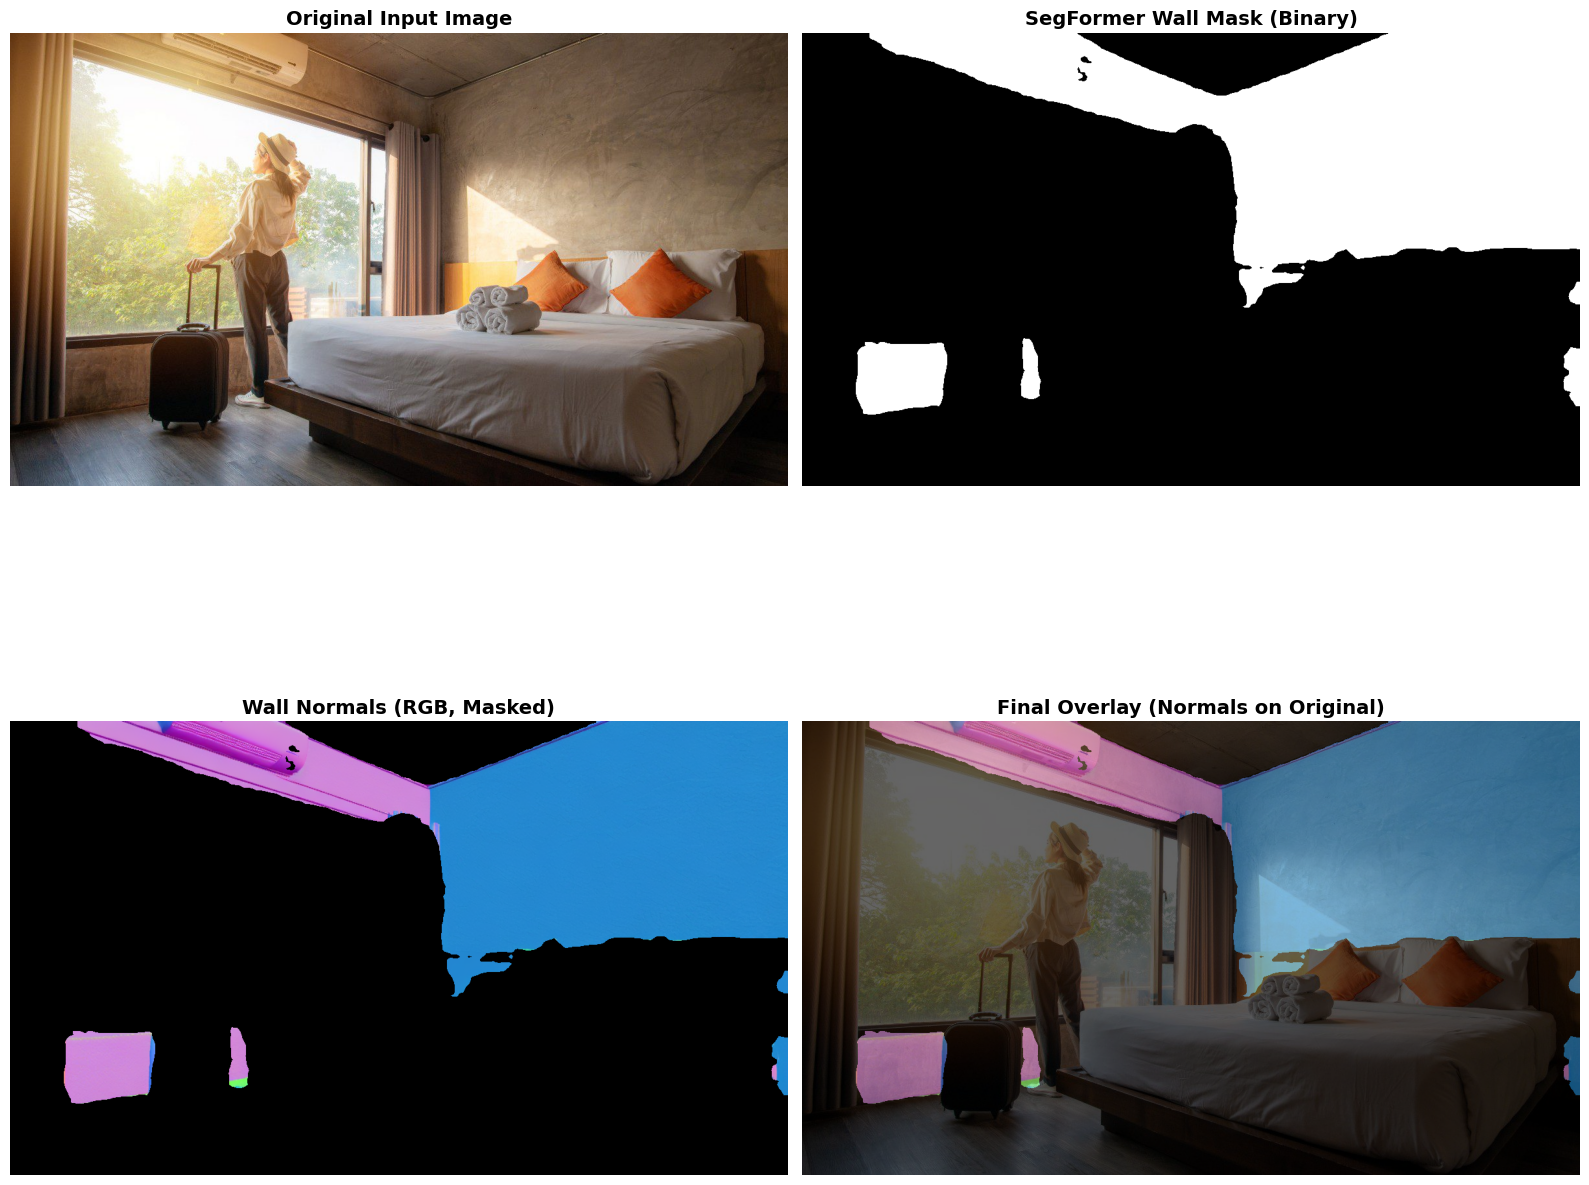


Saved overlay to: /Users/ishan-aiworkspace/Documents/apps/rgb-x/rgb-x_output/batch_output/bed_back_bedroom/bed_back_bedroom_wall_normal_overlay.png


In [28]:
# Test the overlay function on a single image
# Find first entry with complete data (input + normal + segmentation)
test_item = None
for item in image_dataset:
    if item['input_path'] and item['normal_path'] and item['wall_confidence_path']:
        if item['input_path'].exists() and item['normal_path'].exists() and item['wall_confidence_path'].exists():
            test_item = item
            break

if test_item:
    print(f"Testing on: {test_item['image_name']}\n")
    
    # Create the overlay visualization
    result = create_wall_normal_overlay(
        input_image_path=test_item['input_path'],
        normal_npy_path=test_item['normal_path'],
        wall_confidence_npy_path=test_item['wall_confidence_path'],
        confidence_threshold=0.5,
        blend_alpha=0.6
    )
    
    # Display results in a 2×2 grid
    fig, axes = plt.subplots(2, 2, figsize=(16, 16))
    
    # Top-left: Original input image
    axes[0, 0].imshow(result['input_image'])
    axes[0, 0].set_title('Original Input Image', fontsize=14, fontweight='bold')
    axes[0, 0].axis('off')
    
    # Top-right: Wall mask visualization
    axes[0, 1].imshow(result['wall_mask'], cmap='gray')
    axes[0, 1].set_title('SegFormer Wall Mask (Binary)', fontsize=14, fontweight='bold')
    axes[0, 1].axis('off')
    
    # Bottom-left: Masked wall normals (RGB)
    axes[1, 0].imshow(result['wall_normals_rgb'])
    axes[1, 0].set_title('Wall Normals (RGB, Masked)', fontsize=14, fontweight='bold')
    axes[1, 0].axis('off')
    
    # Bottom-right: Final overlay composite
    axes[1, 1].imshow(result['overlay'])
    axes[1, 1].set_title('Final Overlay (Normals on Original)', fontsize=14, fontweight='bold')
    axes[1, 1].axis('off')
    
    plt.tight_layout()
    plt.show()
    
    # Save the overlay
    output_path = Path(OUTPUT_DIR) / test_item['image_name'] / f"{test_item['image_name']}_wall_normal_overlay.png"
    output_path.parent.mkdir(parents=True, exist_ok=True)
    result['overlay'].save(output_path)
    print(f"\nSaved overlay to: {output_path}")
    
else:
    print("No complete dataset entry found (need input + normal + wall_confidence)")
    print("Make sure to run SegFormer processing first (cell 13) and update dataset (cell 14)")

### 4.1. Visualize Normal Vectors as RGB Image
Normal vectors (x, y, z) can be visualized as RGB colors

In [29]:
def normalize_for_visualization(normals):
    """
    Convert normal vectors to RGB visualization.
    
    IMPORTANT: The model's pipeline already denormalizes the output from [-1, 1] to [0, 1]
    and does NOT apply gamma correction to normal maps. Therefore, the .npy files
    are already in the correct [0, 1] range for visualization.
    
    See: rgbx/rgb2x/pipeline_rgb2x.py lines 800-815
    - do_denormalize = True (converts [-1,1] to [0,1])
    - do_gamma_correction = False for normal maps
    """
    # Model outputs are already in [0, 1] - just clip to ensure valid range
    vis = np.clip(normals, 0, 1)
    return vis

def normals_to_rgb(normals):
    """
    Convert normal vectors to RGB image for visualization.
    Returns PIL Image.
    
    This matches the model's PNG preview generation:
    img_png = (np.clip(img_np, 0, 1) * 255).astype(np.uint8)
    """
    vis = normalize_for_visualization(normals)
    rgb_array = (vis * 255).astype(np.uint8)
    return Image.fromarray(rgb_array)

print("Visualization functions defined!")
print("NOTE: Updated to match model's output format (already in [0, 1] range)")

Visualization functions defined!
NOTE: Updated to match model's output format (already in [0, 1] range)


In [24]:
# Visualize the sample normal vector array
if npy_files:
    # Load corresponding input image if available
    image_name = sample_file.stem.replace(NORMAL_NPY_SUFFIX.replace('.npy', ''), '')
    possible_extensions = ['.jpg', '.jpeg', '.png', '.JPG', '.JPEG', '.PNG']
    
    input_image = None
    for ext in possible_extensions:
        image_path = Path(INPUT_IMAGES_DIR) / f"{image_name}{ext}"
        if image_path.exists():
            input_image = Image.open(image_path)
            print(f"Found input image: {image_path.name}")
            break
    
    # Create visualization
    normal_rgb = normals_to_rgb(normal_array)
    
    # Plot
    if input_image is not None:
        fig, axes = plt.subplots(1, 2, figsize=(16, 8))
        axes[0].imshow(input_image)
        axes[0].set_title("Original Input Image", fontsize=14, fontweight='bold')
        axes[0].axis('off')
        
        axes[1].imshow(normal_rgb)
        axes[1].set_title("Normal Vectors (as RGB)", fontsize=14, fontweight='bold')
        axes[1].axis('off')
    else:
        fig, ax = plt.subplots(1, 1, figsize=(10, 8))
        ax.imshow(normal_rgb)
        ax.set_title("Normal Vectors (as RGB)", fontsize=14, fontweight='bold')
        ax.axis('off')
        print("Note: Could not find corresponding input image")
    
    plt.tight_layout()
    plt.show()
    
    # Save visualization
    output_path = Path(OUTPUT_DIR) / f"{sample_file.stem}_visualization.png"
    normal_rgb.save(output_path)
    print(f"\nSaved visualization to: {output_path}")
else:
    print("No files to visualize!")

NameError: name 'npy_files' is not defined

## 5. Wall Normal Extraction and Overlay Visualization

This section creates visualizations that combine SegFormer wall segmentation with RGB->X normal maps.

**What we're doing:**
1. Use SegFormer confidence maps to identify wall pixels
2. Extract normal vectors only for wall regions
3. Visualize wall normals as RGB colors
4. Overlay this RGB visualization on top of the original input image

This creates a composite image showing the normal vector directions of walls, making it easy to understand wall orientations in the scene.

### Core Function: Create Wall Normal Overlay
This function loads the three data sources (input image, normals, wall confidence), creates a binary mask from the confidence map, extracts wall normals, and blends them onto the original image.

In [30]:
def create_wall_normal_overlay(input_image_path, normal_npy_path, wall_confidence_npy_path, 
                               confidence_threshold=0.6, blend_alpha=0.6):
    """
    Create an overlay visualization of wall normals on the original image.
    
    This function:
    1. Loads the original image, normal map, and wall confidence map
    2. Creates a binary mask from the confidence map using the threshold
    3. Extracts normals only for wall pixels
    4. Converts wall normals to RGB visualization
    5. Overlays the RGB wall normals on the original image
    
    Args:
        input_image_path: Path to original RGB image
        normal_npy_path: Path to normal.npy file (H×W×3 array, range [0,1])
        wall_confidence_npy_path: Path to wall_confidence.npy (H×W array, range [0,1])
        confidence_threshold: Threshold for wall classification (default: 0.5)
        blend_alpha: Alpha value for blending overlay (0=original, 1=full overlay, default: 0.6)
    
    Returns:
        dict containing:
            - 'overlay': PIL Image of the final composite
            - 'wall_normals_rgb': PIL Image of masked wall normals (RGB)
            - 'wall_mask': numpy array of binary wall mask (H×W, bool)
            - 'input_image': PIL Image of original input
    """
    # Load input image
    input_img = Image.open(input_image_path).convert('RGB')
    input_array = np.array(input_img)
    
    # Load normal map
    normals = np.load(normal_npy_path)
    
    # Load wall confidence map
    wall_confidence = np.load(wall_confidence_npy_path)
    
    # Create binary wall mask
    wall_mask = wall_confidence > confidence_threshold
    
    # Convert normals to RGB (using existing function)
    normals_rgb_array = (np.clip(normals, 0, 1) * 255).astype(np.uint8)
    
    # Create masked wall normals (set non-wall pixels to black)
    masked_wall_normals = normals_rgb_array.copy()
    masked_wall_normals[~wall_mask] = 0  # Set non-wall pixels to black
    
    # Convert to PIL Images
    wall_normals_rgb = Image.fromarray(masked_wall_normals)
    
    # Create overlay using alpha blending
    # Method: composite = (1-alpha) * original + alpha * wall_normals
    overlay = Image.blend(input_img, wall_normals_rgb, alpha=blend_alpha)
    
    return {
        'overlay': overlay,
        'wall_normals_rgb': wall_normals_rgb,
        'wall_mask': wall_mask,
        'input_image': input_img
    }

print("Wall normal overlay function created!")
print("Usage: create_wall_normal_overlay(input_path, normal_path, confidence_path)")


Wall normal overlay function created!
Usage: create_wall_normal_overlay(input_path, normal_path, confidence_path)


### Test Visualization on Single Image
Test the overlay function on one image and display a 2×2 comparison grid showing: original image, wall mask, masked normals, and final overlay.

Testing on: bed_back_bedroom



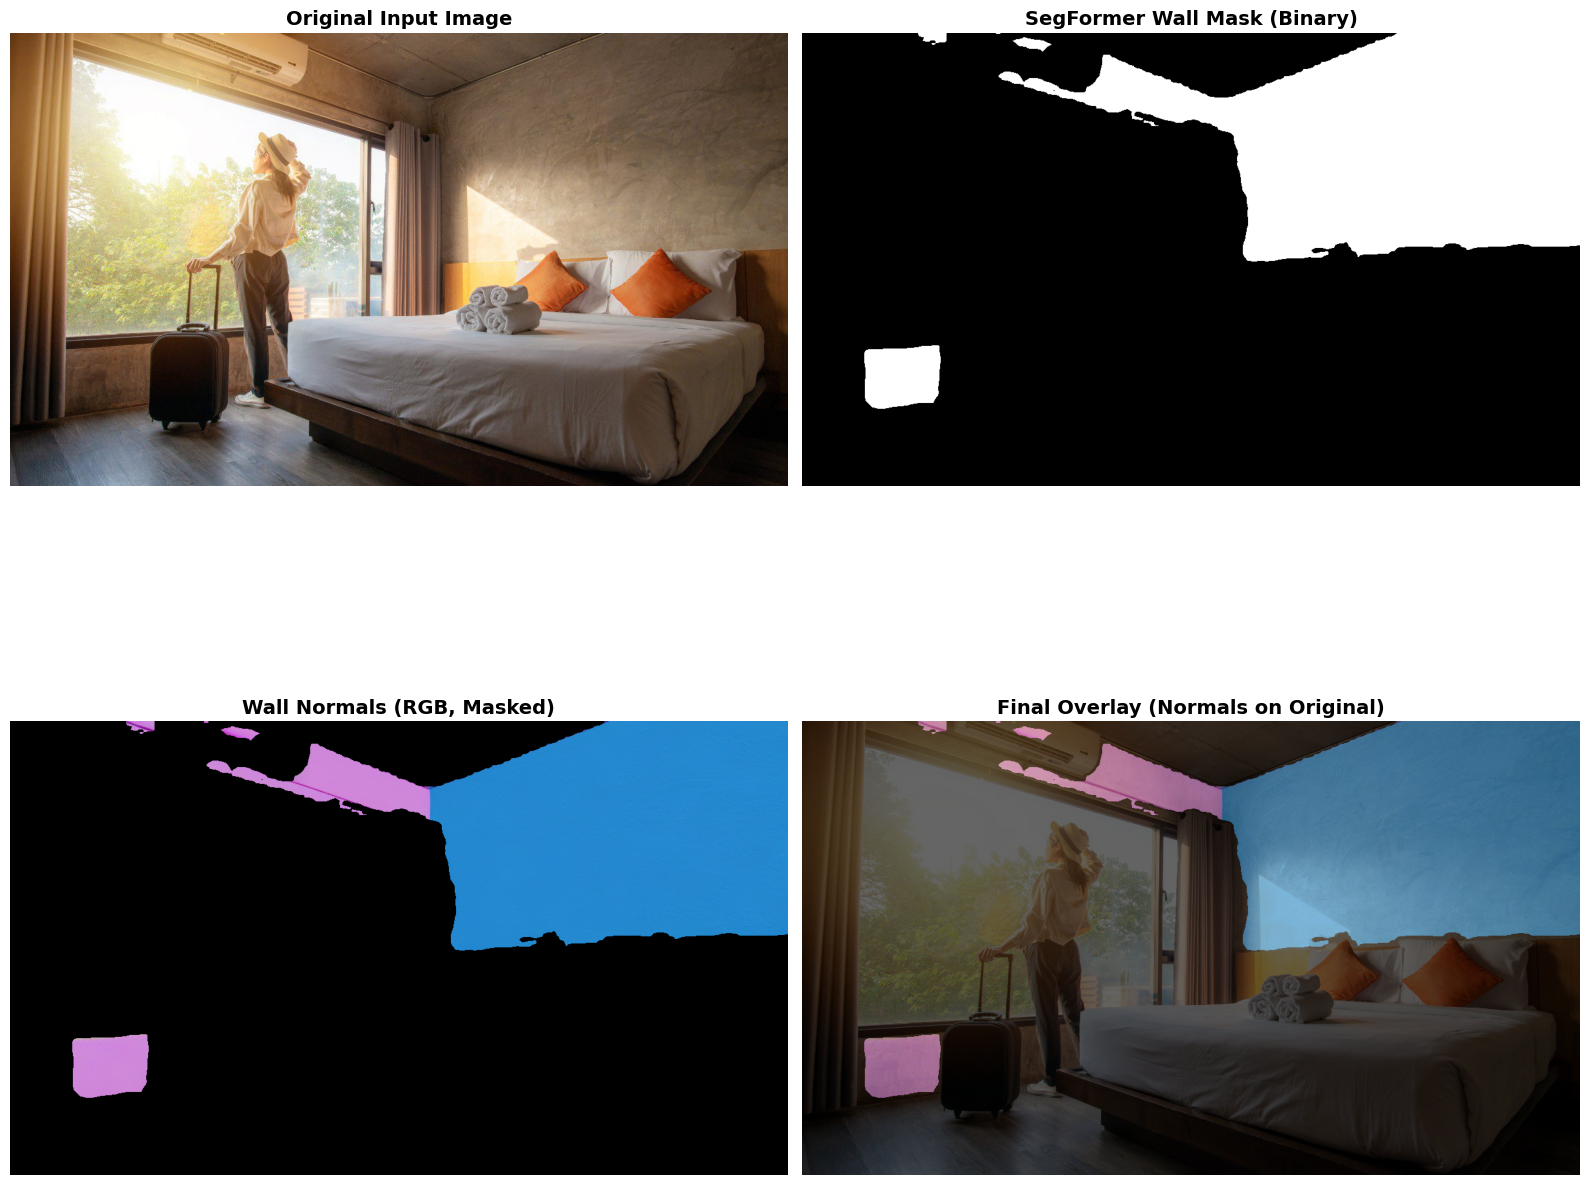


Saved overlay to: /Users/ishan-aiworkspace/Documents/apps/rgb-x/rgb-x_output/batch_output/bed_back_bedroom/bed_back_bedroom_wall_normal_overlay.png


In [31]:
# Test the overlay function on a single image
# Find first entry with complete data (input + normal + segmentation)
test_item = None
for item in image_dataset:
    if item['input_path'] and item['normal_path'] and item['wall_confidence_path']:
        if item['input_path'].exists() and item['normal_path'].exists() and item['wall_confidence_path'].exists():
            test_item = item
            break

if test_item:
    print(f"Testing on: {test_item['image_name']}\n")
    
    # Create the overlay visualization
    result = create_wall_normal_overlay(
        input_image_path=test_item['input_path'],
        normal_npy_path=test_item['normal_path'],
        wall_confidence_npy_path=test_item['wall_confidence_path'],
        confidence_threshold=0.9,
        blend_alpha=0.6
    )
    
    # Display results in a 2×2 grid
    fig, axes = plt.subplots(2, 2, figsize=(16, 16))
    
    # Top-left: Original input image
    axes[0, 0].imshow(result['input_image'])
    axes[0, 0].set_title('Original Input Image', fontsize=14, fontweight='bold')
    axes[0, 0].axis('off')
    
    # Top-right: Wall mask visualization
    axes[0, 1].imshow(result['wall_mask'], cmap='gray')
    axes[0, 1].set_title('SegFormer Wall Mask (Binary)', fontsize=14, fontweight='bold')
    axes[0, 1].axis('off')
    
    # Bottom-left: Masked wall normals (RGB)
    axes[1, 0].imshow(result['wall_normals_rgb'])
    axes[1, 0].set_title('Wall Normals (RGB, Masked)', fontsize=14, fontweight='bold')
    axes[1, 0].axis('off')
    
    # Bottom-right: Final overlay composite
    axes[1, 1].imshow(result['overlay'])
    axes[1, 1].set_title('Final Overlay (Normals on Original)', fontsize=14, fontweight='bold')
    axes[1, 1].axis('off')
    
    plt.tight_layout()
    plt.show()
    
    # Save the overlay
    output_path = Path(OUTPUT_DIR) / test_item['image_name'] / f"{test_item['image_name']}_wall_normal_overlay.png"
    output_path.parent.mkdir(parents=True, exist_ok=True)
    result['overlay'].save(output_path)
    print(f"\nSaved overlay to: {output_path}")
    
else:
    print("No complete dataset entry found (need input + normal + wall_confidence)")
    print("Make sure to run SegFormer processing first (cell 13) and update dataset (cell 14)")



### Batch Processing Function
Process all dataset entries with complete data (input + normal + segmentation) and save overlay visualizations for each image.

In [32]:
def process_wall_overlay_batch(dataset, confidence_threshold=0.5, blend_alpha=0.6, verbose=True):
    """
    Process all images in the dataset and create wall normal overlay visualizations.
    
    Args:
        dataset: List of dataset entries from build_image_dataset()
        confidence_threshold: Threshold for wall classification (default: 0.5)
        blend_alpha: Alpha value for blending overlay (default: 0.6)
        verbose: Print progress messages (default: True)
    
    Returns:
        dict with processing statistics:
            - 'processed': Number of images successfully processed
            - 'skipped': Number of images skipped (missing data)
            - 'errors': List of error messages
    """
    results = {'processed': 0, 'skipped': 0, 'errors': []}
    
    # Filter dataset for entries with complete data
    complete_entries = [
        item for item in dataset 
        if item['input_path'] and item['normal_path'] and item['wall_confidence_path']
        and item['input_path'].exists() and item['normal_path'].exists() and item['wall_confidence_path'].exists()
    ]
    
    if verbose:
        print(f"Found {len(complete_entries)} entries with complete data")
        print(f"Skipping {len(dataset) - len(complete_entries)} entries with missing data\n")
    
    results['skipped'] = len(dataset) - len(complete_entries)
    
    for idx, item in enumerate(complete_entries):
        if verbose:
            print(f"[{idx+1}/{len(complete_entries)}] Processing: {item['image_name']}")
        
        try:
            # Create overlay visualization
            result = create_wall_normal_overlay(
                input_image_path=item['input_path'],
                normal_npy_path=item['normal_path'],
                wall_confidence_npy_path=item['wall_confidence_path'],
                confidence_threshold=confidence_threshold,
                blend_alpha=blend_alpha
            )
            
            # Save the overlay
            output_dir = Path(OUTPUT_DIR) / item['image_name']
            output_dir.mkdir(parents=True, exist_ok=True)
            
            overlay_path = output_dir / f"{item['image_name']}_wall_normal_overlay.png"
            result['overlay'].save(overlay_path)
            
            # Optionally save the masked wall normals too
            wall_normals_path = output_dir / f"{item['image_name']}_wall_normals_masked.png"
            result['wall_normals_rgb'].save(wall_normals_path)
            
            results['processed'] += 1
            
            if verbose:
                print(f"  ✓ Saved: {overlay_path.name}")
                
        except Exception as e:
            error_msg = f"{item['image_name']}: {str(e)}"
            results['errors'].append(error_msg)
            if verbose:
                print(f"  ✗ Error: {str(e)}")
    
    if verbose:
        print(f"\n{'='*60}")
        print(f"BATCH PROCESSING COMPLETE")
        print(f"{'='*60}")
        print(f"Processed: {results['processed']}")
        print(f"Skipped: {results['skipped']}")
        print(f"Errors: {len(results['errors'])}")
        if results['errors']:
            print(f"\nError details:")
            for err in results['errors']:
                print(f"  - {err}")
    
    return results

print("Batch processing function ready!")
print("Usage: process_wall_overlay_batch(image_dataset)")


Batch processing function ready!
Usage: process_wall_overlay_batch(image_dataset)


### Run Batch Processing
Execute the batch processor on the entire dataset to generate wall normal overlays for all images.

In [33]:
process_wall_overlay_batch(image_dataset)

Found 12 entries with complete data
Skipping 0 entries with missing data

[1/12] Processing: bed_back_bedroom
  ✓ Saved: bed_back_bedroom_wall_normal_overlay.png
[2/12] Processing: fluted_walls_living
  ✓ Saved: fluted_walls_living_wall_normal_overlay.png
[3/12] Processing: complex_living
  ✓ Saved: complex_living_wall_normal_overlay.png
[4/12] Processing: perspective_living
  ✓ Saved: perspective_living_wall_normal_overlay.png
[5/12] Processing: simple_living
  ✓ Saved: simple_living_wall_normal_overlay.png
[6/12] Processing: simple_living_2
  ✓ Saved: simple_living_2_wall_normal_overlay.png
[7/12] Processing: no_walls_living
  ✓ Saved: no_walls_living_wall_normal_overlay.png
[8/12] Processing: simple_living_3
  ✓ Saved: simple_living_3_wall_normal_overlay.png
[9/12] Processing: obstacle_course_living
  ✓ Saved: obstacle_course_living_wall_normal_overlay.png
[10/12] Processing: room1
  ✓ Saved: room1_wall_normal_overlay.png
[11/12] Processing: living_small_walls
  ✓ Saved: living_smal

{'processed': 12, 'skipped': 0, 'errors': []}